# Experiments from October 12 on
See tex/main.pdf, Sections 2.4 to 2.6. 

In [17]:
%run base.ipynb

mare


## Union bound

We plot
\begin{equation}
\mathbb E_D[R(\hat h_D) - \hat R_D(\hat h_D)] \le \sqrt{\frac{d}{n}}
\end{equation}
obtained by Theorem 2.5 in Section 2 and $\log \vert\mathcal H_d\vert \le d$.

[checkpoint] bound: "unionbound" -> union_bound, params: []


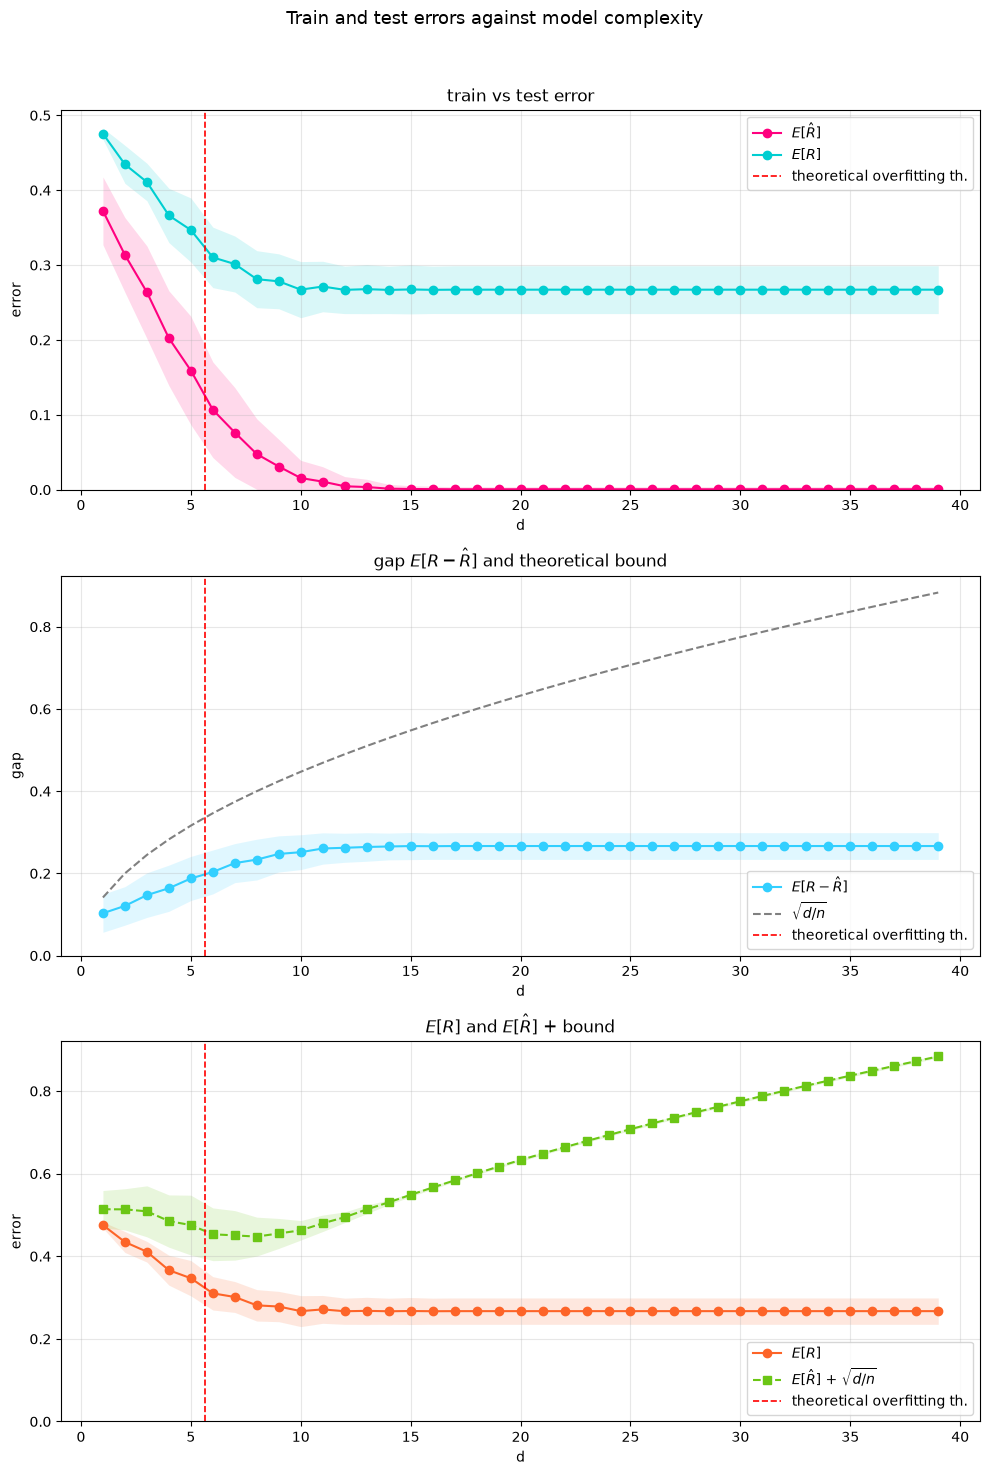

In [11]:
# MODEL
mymodel = DecisionTreeClassifier

# PARAMETERS
supp_size = 10_000
data_size_test = 200_000
data_size_tr = 50
noise_std = 3
num_iter = 100
num_crossings = 10

from functools import partial
mysine = partial(sine, m = num_crossings)

# build test set
x_test = sample_x(data_size_test, supp_size)
y_test = sample_y(x = x_test, f = mysine, sigma = noise_std)

# build models and do plots
hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n = data_size_tr, sigma = noise_std, T = num_iter, model = mymodel,
    f = mysine,
    N = supp_size)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
      n = data_size_tr, sigma = noise_std, T= num_iter, model = mymodel, 
      bound_name = "unionbound", bound_params = {}
      )

## Rademacher + Massart

We plot

\begin{equation}
\mathbb E_D[R(\hat h_D) - \hat R_D(\hat h_D)] \le \min\left\{\sqrt{\frac{d}{n}}, 1\right\}
\end{equation}

obtained from $N(D) \le \min\{\vert \mathcal H\vert, 2^n\}$, equation (58). 

[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []


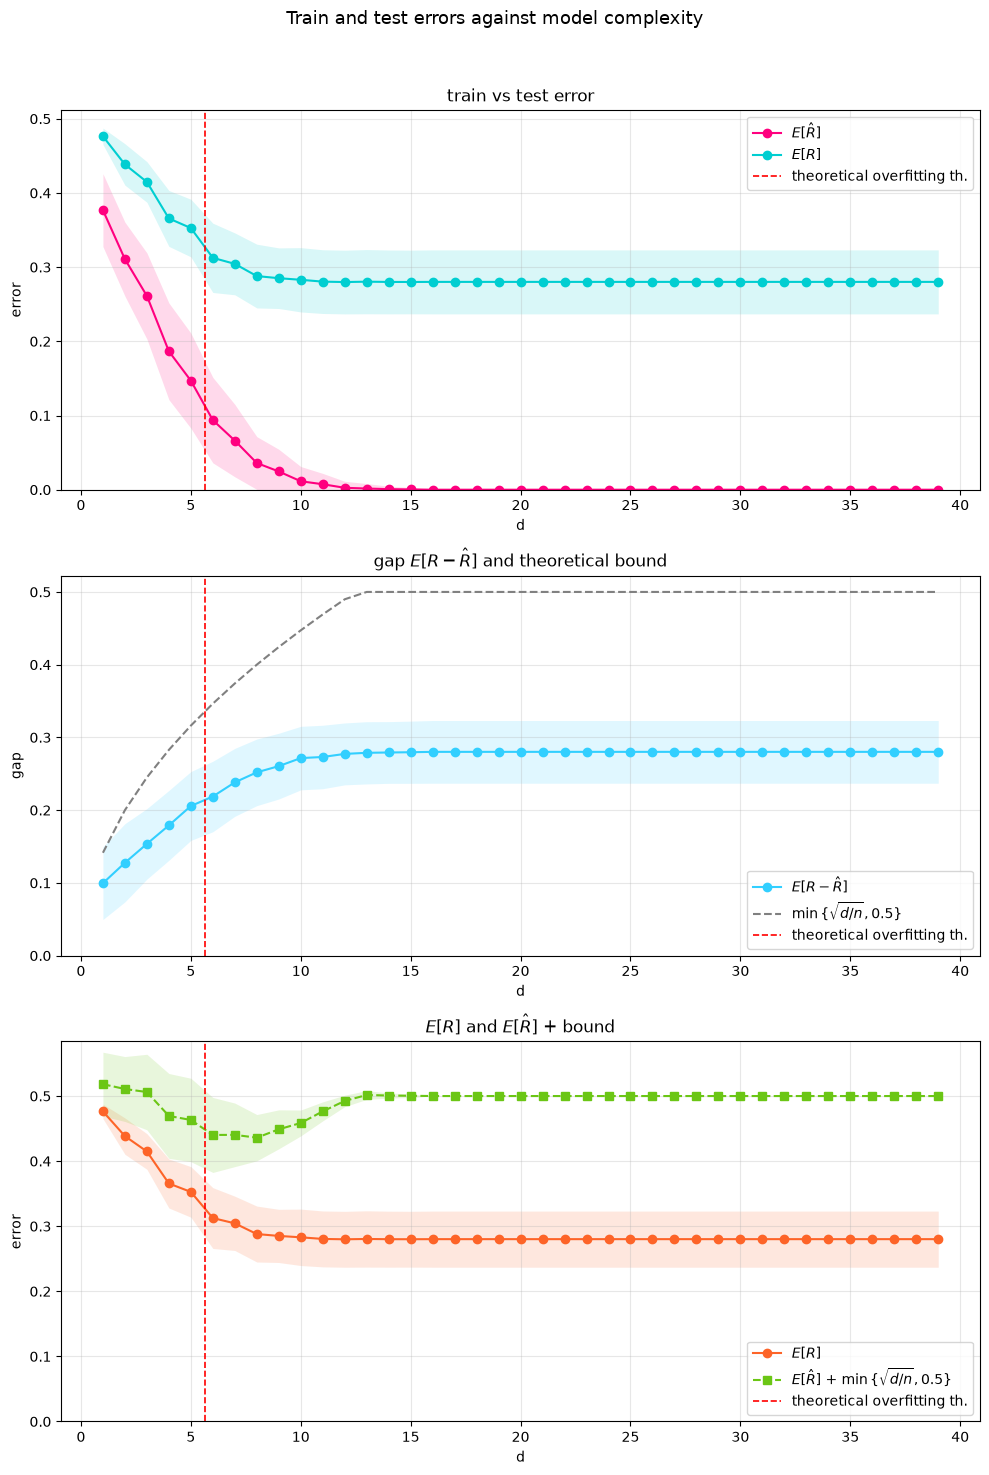

In [12]:
# build models and do plots
hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n = data_size_tr, sigma = noise_std, T = num_iter, model = mymodel,
    f = mysine,
    N = supp_size)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
      n = data_size_tr, sigma = noise_std, T= num_iter, model = mymodel, 
      bound_name = "rademmassart", bound_params = {}
      )

### vedi che non si sposta con il rumore!

[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []
[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []
[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []


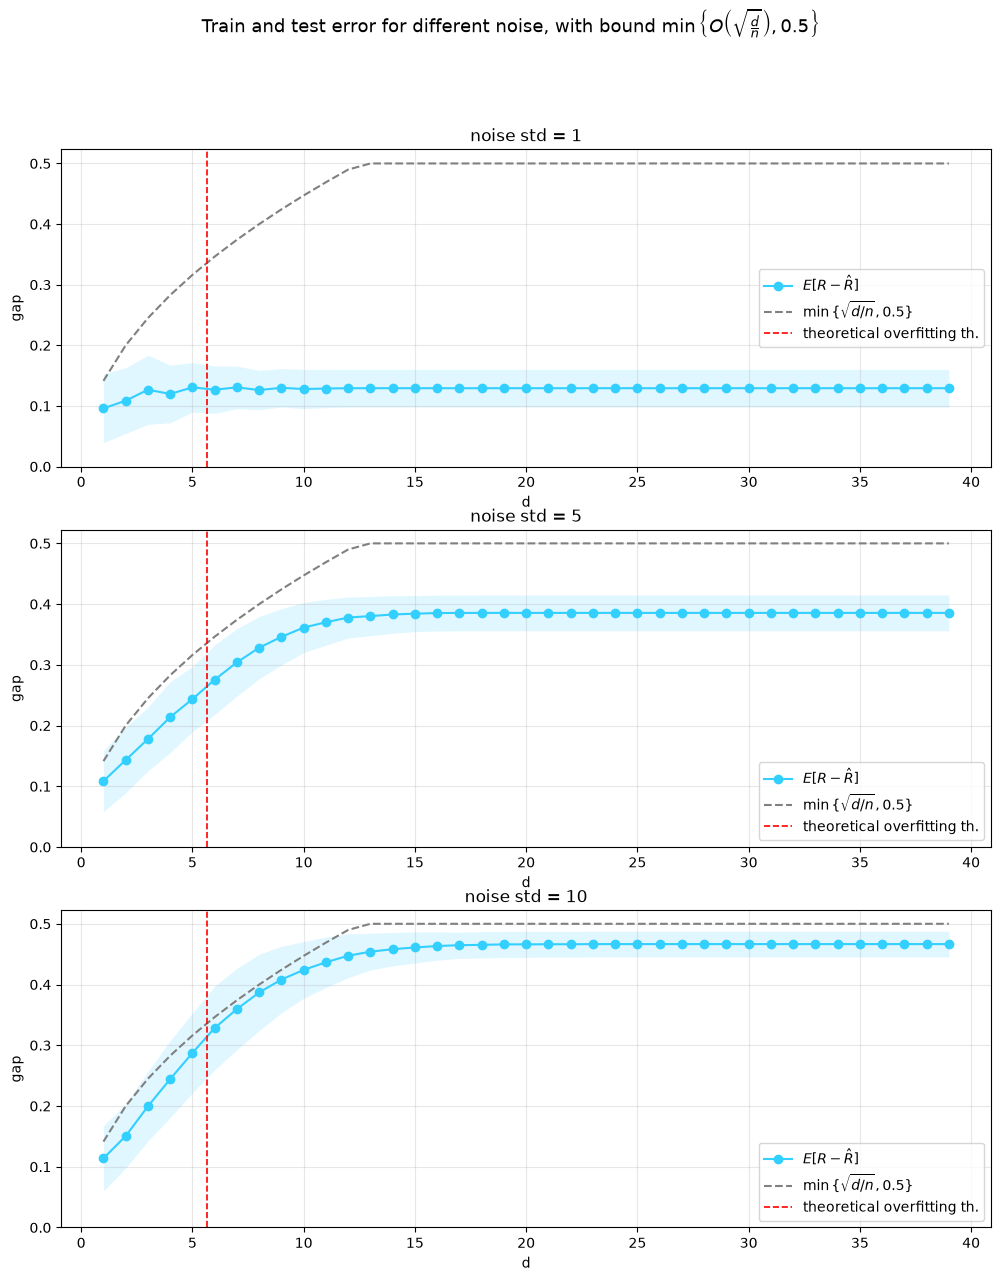

In [13]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(3, 1, figsize=(12, 14))
fig.suptitle(r'Train and test error for different noise, with bound $\min\left\{O\left(\sqrt{\frac{d}{n}}\right), 0.5\right\}$', fontsize=13)

# noises
my_noise_stds = [1, 5, 10]

for ax, my_noise_std in zip(axs.flat, my_noise_stds):
    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y(x=x_test, f=mysine, sigma=my_noise_std)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, sigma=my_noise_std, T=num_iter, model=mymodel, f=mysine, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, sigma=my_noise_std, T=num_iter, model=mymodel, 
          one=False, three=False, axes=[ax],
          bound_name = "rademmassart", bound_params = {})
    ax.set_title(f'noise std = {my_noise_std}')

# Runtime ~2 min for 3 noise stds

## Bounds with the best risk

The bound is 

\begin{equation}

 \min\left\{ 
\sqrt{\frac{(A_{\mathcal H}+\sigma^2)\log \vert\mathcal H \vert}{n}} + \frac{\log\vert\mathcal H \vert}{n} ,
\sqrt{A_{\mathcal H}+\sigma^2}+0.5 \right\}

\end{equation}

In [43]:
# MODEL
mymodel = DecisionTreeClassifier

# PARAMETERS
supp_size = 10_000
data_size_test = 200_000
data_size_tr = 50
num_iter = 100
num_crossings = 10
noise_par = 0.8

from functools import partial
mysine = partial(sine, m = num_crossings)

Let's first see the Bayes risk (irreducible noise), the minimum risk achievable by our hypotheses, and their difference (approximation error). 

In [ ]:
# same depths that main_loop and plots use
depths, _ = get_depths_list(np.log2(data_size_tr), mymodel)

R_star_d = dp_R_star_d(mysine, depths, N = supp_size, p = noise_par)

R_star = 1-noise_par

A_d = R_star_d - R_star

def plot_noise_approxerr(ax, depths, R_star_d, R_star, n):
    '''
    R^*_d, the quantity that enters the bound, as a thick line;
    Bayes risk R^* and approximation error A_d = R^*_d - R^* as thinner lines.
    '''
    ax.plot(depths, R_star_d, color='#FD6428', linewidth=3.5, marker='o', markersize=6,
            label=r'$R^*_d$', zorder=3)
    ax.plot(depths, R_star_d - R_star, color='#FF007F', linewidth=1.2, marker='o', markersize=3,
            label=r'$A_d = R^*_d - R^*$')
    ax.axhline(R_star, color='gray', linestyle='--', linewidth=1.2, label=r'$R^*$ (Bayes/ noise)')
    ax.axvline(np.log2(n), color='red', linestyle='--', linewidth=1.2, label='theoretical overfitting th.')
    ax.set_ylim(bottom=-0.02)   # so that A_d = 0 stays visible
    ax.set_xlabel('d'); ax.set_ylabel('risk')
    ax.legend(); ax.grid(True, alpha=0.3)

fig, ax = plt.subplots(figsize=(10, 5))
plot_noise_approxerr(ax, depths, R_star_d, R_star, data_size_tr)
ax.set_title(f'Noise and approximation error of trees at different depths (p = {noise_par})')
plt.show()

In [42]:
%run base.ipynb

mare


[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']


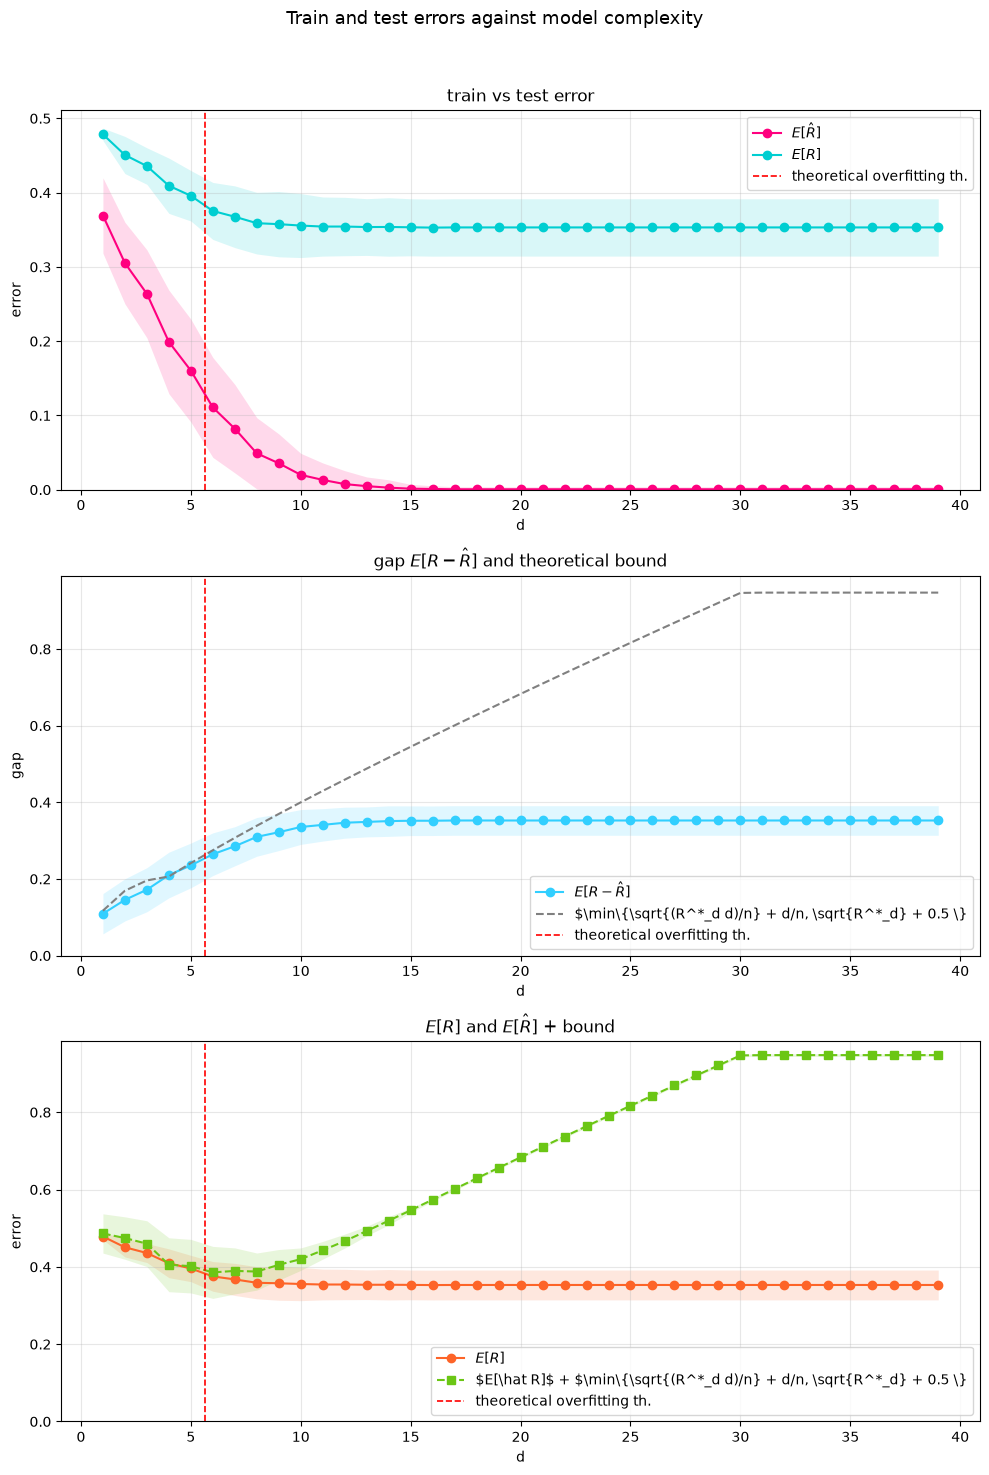

In [37]:

# build test set
x_test = sample_x(data_size_test, supp_size)
y_test = sample_y_bernoulli(x = x_test, f = mysine, p = noise_par)

# build models and do plots
hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n = data_size_tr, p = noise_par, T = num_iter, model = mymodel,
    f = mysine, noise_type = "bernoulli",
    N = supp_size)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
      n = data_size_tr, noise_type = "bernoulli", p = noise_par, T= num_iter, model = mymodel, 
      bound_name = "noiseapproxerr", bound_params = {"R_star_d": R_star_d}
      )

Let's see it changing!

In [ ]:
# noises
my_noise_pars = [0.95, 0.8, 0.6]

# R^*_d for each noise level, to reuse in the bounds below
R_star_d_by_p = {}

fig, axs = plt.subplots(3, 1, figsize=(12, 14), sharey=True)
fig.suptitle('Noise and approximation error of trees at different depths', fontsize=13)

for ax, my_noise_par in zip(axs, my_noise_pars):
    my_R_star_d = dp_R_star_d(mysine, depths, N = supp_size, p = my_noise_par)
    my_R_star = 1-my_noise_par
    R_star_d_by_p[my_noise_par] = my_R_star_d

    plot_noise_approxerr(ax, depths, my_R_star_d, my_R_star, data_size_tr)
    ax.set_title(f'p = {my_noise_par}')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']
[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']
[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']


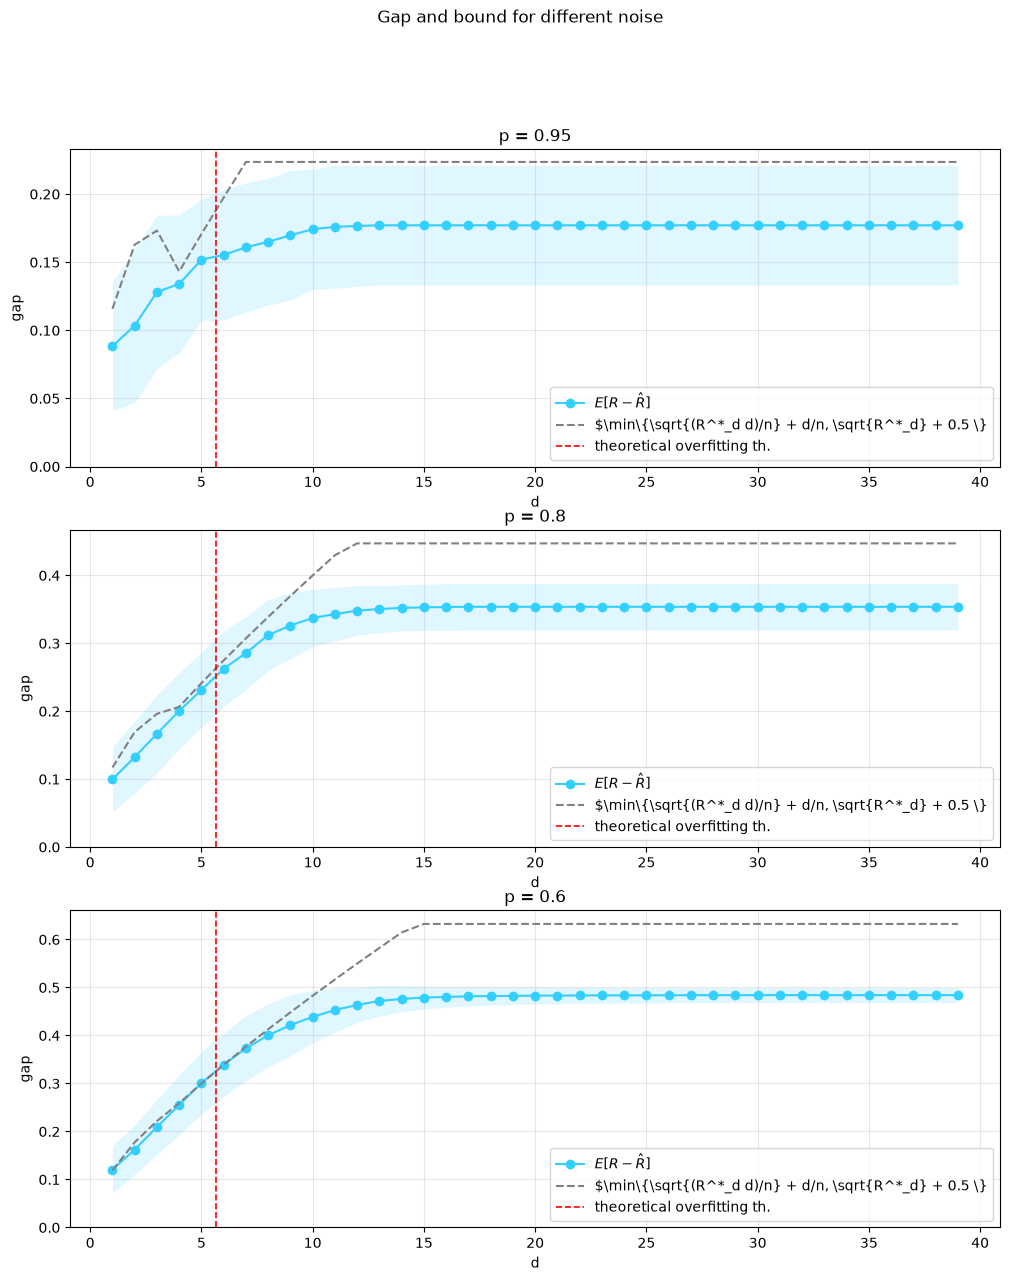

In [45]:
fig, axs = plt.subplots(3, 1, figsize=(12, 14))
fig.suptitle('Gap and bound for different noise')

for ax, my_noise_par in zip(axs.flat, my_noise_pars):
    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y_bernoulli(x=x_test, f=mysine, p=my_noise_par)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, noise_type = "bernoulli",
        p=my_noise_par, T=num_iter, model=mymodel, f=mysine, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, noise_type = "bernoulli", p=my_noise_par, T=num_iter, model=mymodel, 
          one=False, three=False, axes=[ax],
          bound_name = "noiseapproxerr", bound_params = {"R_star_d": R_star_d_by_p[my_noise_par]})
    ax.set_title(f'p = {my_noise_par}')

For each noise level, which of the two terms of the $\min$ is selected at each depth.

In [ ]:
# the two terms of the min in the bound, for each noise level:
# thin dashed lines are the two terms, the thick line is the bound (their min),
# coloured by the term that attains the min at each d
term_colors = {True: '#FF007F', False: '#6BC615'}   # True: first term selected
term_labels = {True: r'$\sqrt{R^*_d\,\log|\mathcal{H}_d|/n} + \log|\mathcal{H}_d|/n$',
               False: r'$\sqrt{R^*_d}$'}

fig, axs = plt.subplots(3, 1, figsize=(12, 14))
fig.suptitle('Which term of the bound is selected, for different noise', fontsize=13)

for ax, my_noise_par in zip(axs.flat, my_noise_pars):
    my_R_star_d = R_star_d_by_p[my_noise_par]
    log_H = np.array([log_card_H(d) for d in depths], dtype=float)
    first = np.sqrt(my_R_star_d * log_H / data_size_tr) + log_H / data_size_tr
    second = np.sqrt(my_R_star_d)
    bound = np.minimum(first, second)
    first_wins = first <= second

    # check that the two terms are exactly the ones of the bound used in plots()
    bound_check = np.vectorize(BOUND_REGISTRY["noiseapproxerr"])(
        depths.astype(float), data_size_tr, R_star_d=my_R_star_d)
    assert np.allclose(bound, bound_check), 'terms differ from noise_approxerr_bound'

    # light background on each interval of d where a term is selected
    run_starts = np.r_[0, np.flatnonzero(np.diff(first_wins)) + 1]
    run_ends = np.r_[run_starts[1:], len(depths)]
    for s, e in zip(run_starts, run_ends):
        ax.axvspan(depths[s] - 0.5, depths[e - 1] + 0.5, color=term_colors[first_wins[s]],
                   alpha=0.07, linewidth=0)

    # the two terms over the whole range
    for wins, term in ((True, first), (False, second)):
        ax.plot(depths, term, color=term_colors[wins], linestyle='--', linewidth=1.2,
                label=term_labels[wins])

    # the bound as two contiguous thick lines, one colour per selected term
    for i in range(len(depths) - 1):
        ax.plot(depths[i:i + 2], bound[i:i + 2], color=term_colors[first_wins[i]],
                linewidth=7, solid_capstyle='round', alpha=0.85)
    for wins in (True, False):
        # empty plot only to get the legend entry of the thick line
        ax.plot([], [], color=term_colors[wins], linewidth=7, alpha=0.85,
                label='bound, ' + ('first' if wins else 'second') + ' term selected')

    ax.axvline(np.log2(data_size_tr), color='red', linestyle='--', linewidth=1.2,
               label='theoretical overfitting th.')
    ax.set_ylim(0, 1.3 * bound.max())
    ax.set_title(f'p = {my_noise_par}')
    ax.set_xlabel('d'); ax.set_ylabel('bound')
    ax.legend(loc='lower right'); ax.grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()